# Compare five flotation kinetic models on shared evidence

**Question:** How does each published kinetic model's fitting error compare with its continuous-bank projection error?

Level: 3. Prerequisites: Levels 1 and 2 in this topic. Reading time: 24 minutes.

## Objectives

Compare five cited kinetic forms on identical batch evidence, then evaluate bank projection separately against the engine's exact rate-distributed reference.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

For the level 3 02-flotation lesson, record the pinned versions before analysis so the environment behind its tables and figures can be reconstructed.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; `data/derived/cases/copper_molybdenum.json`, an authored scenario under the MIT project licence. Both observations and exact-reference response are generated by the model, not measured plant data. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

The candidate forms are first order, Kelsall fast/slow, Klimpel uniform-rate, gamma and stretched exponential. Each compresses heterogeneous flotation rates differently. OreFlow evaluates the same virtual batch curve and compares continuous-bank predictions; a fitted curve alone cannot identify a unique mechanism.

## Comparison

First-order kinetics (Kelsall (1961) provides a classical fast/slow baseline. Kelsall and distributed-rate forms represent heterogeneity with more parameters. OreFlow implements five forms in `pipeline/engine/kinetics.py` and measures both batch fit error and bank projection error against its exact rate distribution. This demonstrates a controlled method comparison, not superiority on plant data or a novel algorithm.

Load one committed kinetic record so every model uses the same observations and predictions.

In [2]:
# Load one committed kinetic record so every model uses the same observations and predictions.
case_record = json.loads(
    (repo / "data/derived/cases/copper_molybdenum.json").read_text(encoding="utf-8")
)
kinetics = case_record["variants"][0]["trace"]["methods"]["kinetics"]
models = kinetics["models"]
print("status:", kinetics["status"], "| payable:", kinetics["species"])
print("bank residence (min):", kinetics["bank"]["residence_min"])
print("exact bank recovery (%):", kinetics["bank"]["exact_true_flotation_pct"])


status: computed | payable: Cu
bank residence (min): 29.161577021309544
exact bank recovery (%): 93.9822410776771


Compare batch fit and bank error side by side; their rankings need not match.

In [3]:
# Compare batch fit and bank error side by side; their rankings need not match.
scores = pd.DataFrame(
    [
        {
            "model": m["id"],
            "batch RMSE (points)": m["rmse_pct"],
            "bank prediction (%)": m["bank_projection_pct"],
            "bank error (points)": m["lumping_error_pct"],
            "extrapolation gap (points)": m["ultimate_gap_pct"],
        }
        for m in models
    ]
)
display(scores.set_index("model").round(3).sort_values("batch RMSE (points)"))


,batch RMSE (points),bank prediction (%),bank error (points),extrapolation gap (points)
model,,,,
kelsall,0.028,92.662,-1.320,4.540
gamma,0.146,92.951,-1.032,7.034
klimpel,0.398,92.665,-1.318,9.604
stretched_exponential,0.667,90.005,-3.977,1.724
first_order,1.640,87.393,-6.590,0.471


Plot fitted models over the shared batch observations. The next figure evaluates their bank projections against the exact engine reference.

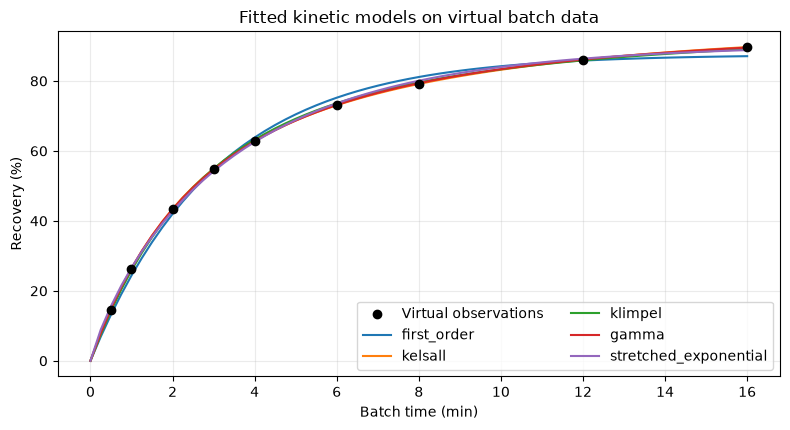

In [4]:
# Plot fitted models over the shared batch observations.
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.scatter(
    kinetics["times_min"],
    kinetics["batch_recovery_pct"],
    color="black",
    zorder=4,
    label="Virtual observations",
)
for m in models:
    ax.plot(kinetics["dense_times_min"], m["dense_pct"], label=m["id"])
ax.set(
    xlabel="Batch time (min)",
    ylabel="Recovery (%)",
    title="Fitted kinetic models on virtual batch data",
)
ax.grid(True, alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()


Figure 14 in the level 3 02 flotation lesson reports outputs of independently solved operating points. For figure 14 in level 3 02 flotation, each mark is a separate model evaluation at its stated setting. For figure 14 in level 3 02 flotation, check recovery, size and energy against the contract limits. The line in figure 14 only guides comparison.

Compare the bank projections with the exact distributed-rate result. A good batch fit does not guarantee a good projection through a continuous residence-time distribution.

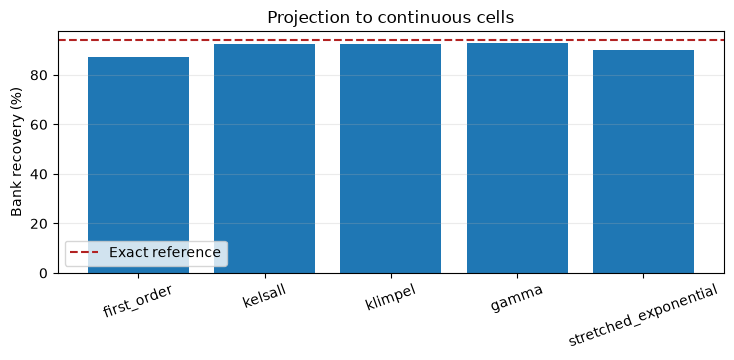

In [5]:
# Compare the bank projections with the exact distributed-rate result.
fig, ax = plt.subplots(figsize=(7.5, 3.7))
ax.bar([m["id"] for m in models], [m["bank_projection_pct"] for m in models])
ax.axhline(
    kinetics["bank"]["exact_true_flotation_pct"],
    color="firebrick",
    linestyle="--",
    label="Exact reference",
)
ax.set(ylabel="Bank recovery (%)", title="Projection to continuous cells")
ax.tick_params(axis="x", rotation=20)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()


Figure 16 in the level 3 02 flotation lesson reports outputs of independently solved operating points. For figure 16 in level 3 02 flotation, each mark is a separate model evaluation at its stated setting. For figure 16 in level 3 02 flotation, check recovery, size and energy against the contract limits. The line in figure 16 only guides comparison.

In the level 3 02 flotation case, the 0.8× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 02 flotation case at 0.8× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 0.8
point_0_8 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_8 = simulate(case.ore, case.plant, point_0_8)
print("throughput (t/h):", round(point_0_8.throughput_tph, 2))
print("recovery (%):", round(response_0_8.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_8.metrics["p80_um"], 2))


throughput (t/h): 512.0
recovery (%): 94.842
product P80 (µm): 150.0


In the level 3 02 flotation case, the 0.9× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 02 flotation case at 0.9× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [7]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 94.143
product P80 (µm): 150.0


In the level 3 02 flotation case, the 1.0× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 02 flotation case at 1.0× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [8]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.0
point_1_0 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_0 = simulate(case.ore, case.plant, point_1_0)
print("throughput (t/h):", round(point_1_0.throughput_tph, 2))
print("recovery (%):", round(response_1_0.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_0.metrics["p80_um"], 2))


throughput (t/h): 640.0
recovery (%): 93.447
product P80 (µm): 150.0


Fit the cited kinetic forms to the virtual batch response and project each fit through the solved rougher-bank residence distribution. This uses OreFlow's published fitting routine; the input remains a model-generated case.

In [9]:
# Fit and project the implemented flotation kinetic models.
from pipeline.engine.kinetics import kinetic_record

kinetic = kinetic_record(
    response_1_0.flotation,
    response_1_0.ore,
    case.nominal.rougher_cells,
    response_1_0.metrics["rougher_recovery_pct"],
)
print("kinetic model fits:", len(kinetic["models"]))
print(
    "exact true-flotation bank recovery (%):", round(kinetic["bank"]["exact_true_flotation_pct"], 3)
)


kinetic model fits: 5
exact true-flotation bank recovery (%): 93.982


In the level 3 02 flotation case, the 1.1× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 02 flotation case at 1.1× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [10]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 704.0
recovery (%): 92.753
product P80 (µm): 150.0


In the level 3 02 flotation case, the 1.2× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 02 flotation case at 1.2× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [11]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.2
point_1_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_2 = simulate(case.ore, case.plant, point_1_2)
print("throughput (t/h):", round(point_1_2.throughput_tph, 2))
print("recovery (%):", round(response_1_2.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_2.metrics["p80_um"], 2))


throughput (t/h): 768.0
recovery (%): 89.749
product P80 (µm): 167.43


In the level 3 02 flotation lesson, plot reading 1 considers in this level 3 02 flotation plot, compare recovery with product P80 across the controlled throughput changes. In the level 3 02 flotation lesson, plot reading 2 considers the two axes keep unlike units separate, so interpret each change as a response of this authored case rather than as an empirical plant trend. In the level 3 02 flotation lesson, plot reading 3 considers the nominal point is included as a reference for the neighboring settings. In the level 3 02 flotation lesson, plot reading 4 considers for compare five flotation kinetic models on shared evidence, the plotted points come from separate engine evaluations, and the lines only guide the eye between tested settings.

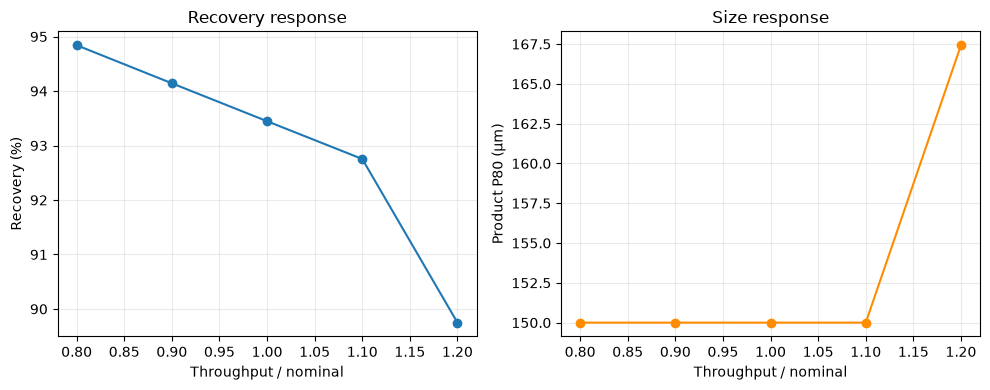

In [12]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_0_8, response_0_9, response_1_0, response_1_1, response_1_2]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


Figure 30 in the level 3 02 flotation lesson reports outputs of independently solved operating points. For figure 30 in level 3 02 flotation, each mark is a separate model evaluation at its stated setting. For figure 30 in level 3 02 flotation, check recovery, size and energy against the contract limits. The line in figure 30 only guides comparison.

At level 3 in 02 flotation, interpretation 1 is that flotation recovery is conditional on the solids and mineral distribution delivered by grinding, the declared floatability parameters, collector response and available residence time. At level 3 in 02 flotation, interpretation 2 is that a higher feed rate changes the time available per unit mass even when cell volume is unchanged. At level 3 in 02 flotation, interpretation 3 is that the model represents that coupling through the bank calculation. At level 3 in 02 flotation, interpretation 4 is that it does not animate individual particles or infer froth behaviour from an image. At level 3 in 02 flotation, interpretation 5 is that compare valuable-mineral recovery with concentrate grade and water recovery, because a recovery increase can also carry more gangue or water. At level 3 in 02 flotation, interpretation 6 is that kinetic forms such as first-order, fast/slow and distributed-rate models can fit similar batch curves while giving different bank projections. At level 3 in 02 flotation, interpretation 7 is that a synthetic exact-rate reference allows internal approximation error to be measured, but it is not a laboratory test. At level 3 in 02 flotation, interpretation 8 is that transfer to a plant requires timed samples, reagent records, air rate, cell geometry and an independently held-out campaign. At level 3 in 02 flotation, extension 1 shows that a defensible kinetic comparison keeps the batch times, fitted ultimate recovery and bank residence assumptions fixed across candidate forms. At level 3 in 02 flotation, extension 2 shows that report residual structure as well as RMSE, since late-time samples can dominate a squared-error fit while early recovery controls a short bank. At level 3 in 02 flotation, extension 3 shows that do not interpret the fitted parameters as unique mineral constants when the observations are generated by the same simulator.

## Results

**Answer:** In this level 3 02 flotation lesson, the executed circuit reports recovery of 93.9822410776771 percent at the first controlled throughput setting for Compare five flotation kinetic models on shared evidence.

The first figure compares fits on the same virtual data; the second compares projections with the exact rate-distributed model. These report approximation error inside OreFlow's engine, not real-world predictive accuracy. Batch fit and bank projection answer different questions.

## Summary

The literature comparison makes both the strength and limit visible: multiple classical forms can fit a synthetic curve, but their bank predictions diverge. OreFlow reports the discrepancy instead of presenting animation as plant dynamics.

## References

- https://doi.org/10.1016/S0301-7516(99)00069-1
- https://doi.org/10.5277/ppmp170128
- https://doi.org/10.1016/j.mineng.2025.109246
- https://doi.org/10.1016/0301-7516(81)90019-3